# Exercise 3 - Lagrangian Initial Conditions

As the input spectrum, I'm using a power law $P_L(k, a_\mathrm{ref}) = A(k/k_0)^n$ declared at $a_\mathrm{ref} = 1$, where $D_1(a_\mathrm{ref}) = 1$, normalized to $\sigma_8 = 0.8$.
- **Cosmology:** flat, $\Omega_{m} = 0.3$, $\Omega_{\Lambda} = 0.7$, $H_0 = 67.4$ km/s/Mpc.
- **Initial epoch:** $a_i = 0.02$. $D_1(a_i)$ and $f_1(a_i)$ come from the growth solver of Exercise 1, whose normalization $D(1)=1$ matches $D_1(a_\mathrm{ref}) = 1$.


Box $L = 1000$ Mpc, $N = 128$. Convention $\delta(\mathbf{x}) = \frac{1}{V}\sum_\mathbf{k}\delta_\mathbf{k}e^{i\mathbf{k}\cdot\mathbf{x}}$, $\langle|\delta_\mathbf{k}|^2\rangle = VP_L$.


In [75]:
import sys
sys.path.insert(0, '../E1') # growth solver of Exercise 1

import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from scipy.integrate import quad

from exercise_1 import growth_ode, E2
from exercise_3 import (k_grid, gaussian_field, power_spectrum, to_x, to_k, zero_nyquist,
                        za_displacement, particle_load, cic_density, cic_window)

OUT = Path('output')
OUT.mkdir(exist_ok=True)

### Parameters

In [76]:
# Box and mesh
N, L = 128, 1000.0 # mesh per dimension, box side in Mpc
seed = 1

# Input spectrum at a_ref = 1
n, k0 = -1.5, 0.1 # slope, pivot in 1/Mpc
sigma8_ref = 0.8 # top-hat rms on 8 Mpc/h at a_ref = 1

# Cosmology and initial epoch
Om0, OL0, h = 0.3, 0.7, 0.674
a_i = 0.02

def P_pow(k, A=1.0):
    return A * (k / k0)**n

def sigma_R(R, A=1.0):
    #Top hat
    W = lambda x: 3 * (np.sin(x) - x * np.cos(x)) / x**3
    integrand = lambda lnk: np.exp(lnk)**3 * P_pow(np.exp(lnk), A) * W(np.exp(lnk) * R)**2 / (2 * np.pi**2)
    return np.sqrt(quad(integrand, np.log(1e-5), np.log(50), limit=500)[0])

A = (sigma8_ref / sigma_R(8 / h))**2
P_ref = lambda k: P_pow(k, A) # P_L(k, a_ref)

# Linear growth at a_i (Exercise 1)
_, D_, f_ = growth_ode(Om0, OL0, ai=1e-5, rtol=1e-10, atol=1e-17, a_eval=[a_i, 1.0])
D1_i, f1_i = D_[0], f_[0]
H0 = 100 * h                                       # km/s/Mpc
calH_i = a_i * H0 * np.sqrt(E2(a_i, Om0, OL0))     # conformal Hubble aH at a_i [km/s/Mpc]

print(f'A = {A:.4e} Mpc^3   D1(a_i) = {D1_i:.5f}   f1(a_i) = {f1_i:.6f}   aH(a_i) = {calH_i:.2f} km/s/Mpc   (D(1) = {D_[1]:.3f})')

A = 8.6406e+03 Mpc^3   D1(a_i) = 0.02567   f1(a_i) = 0.999990   aH(a_i) = 261.04 km/s/Mpc   (D(1) = 1.000)


### a) Gaussian field

The field is drawn with gaussian_field:, such that a real white noise is Fourier transformed and multiplied by $\sqrt{VP_L(k)}$.
This is statistically identical to drawing $\delta_\mathbf{k} = \sqrt{VP_L/2}\,(g_1+ig_2)$ for each pair. Since the noise is real,
$\delta_{-\mathbf{k}} = \delta^*_\mathbf{k}$ holds automatically and self-conjugate cells are real with variance $VP_L$. The zero mode is set to 0.

- **FFT conversion:** numpy's ifftn carries $1/N^3$, the convention above $1/V$, so $\delta(\mathbf{x}) = (N^3/V)\,$\{ifftn}$(\delta_\mathbf{k})$ and $\delta_\mathbf{k} = (V/N^3)\,$\{fftn}$(\delta(\mathbf{x}))$.
- **Nyquist:** $+k_\mathrm{Nyq}$ and $-k_\mathrm{Nyq}$ are the same mode on the mesh, so the derivative $i k$ is ambiguous there. The three Nyquist
  planes are set to zero before any derivative, and this same field is used everywhere below.


### Testing

In [77]:
dk_ref = zero_nyquist(gaussian_field(N, L, P_ref, seed)[0])   # delta_ref,k at a_ref = 1
dx_ref = to_x(dk_ref, L)

dk_neg = np.roll(np.flip(dk_ref, axis=(0, 1, 2)), 1, axis=(0, 1, 2))   # delta at -k
print('Hermitian symmetry  max|delta_-k - conj(delta_k)| / max|delta_k| =',
      f'{np.abs(dk_neg - np.conj(dk_ref)).max() / np.abs(dk_ref).max():.1e}')
print('Imaginary FFT residual  max|Im| / max|Re| =',
      f'{np.abs(np.fft.ifftn(dk_ref).imag).max() / np.abs(np.fft.ifftn(dk_ref).real).max():.1e}')
print(f'Mean density contrast = {dx_ref.mean():.1e}')
print(f'rms of delta on the mesh: {dx_ref.std():.3f} at a_ref,  {D1_i * dx_ref.std():.4f} at a_i')


Hermitian symmetry  max|delta_-k - conj(delta_k)| / max|delta_k| = 3.4e-16
Imaginary FFT residual  max|Im| / max|Re| = 3.3e-16
Mean density contrast = -1.7e-18
rms of delta on the mesh: 1.775 at a_ref,  0.0456 at a_i


### Plotting a slice

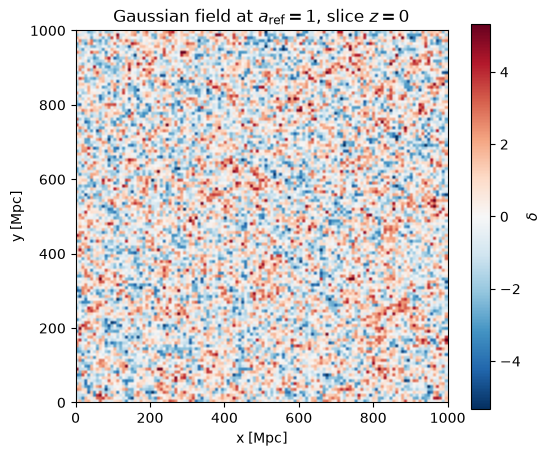

In [78]:
lim = 3 * dx_ref.std()

plt.figure(figsize=(6, 5))
plt.imshow(dx_ref[:, :, 0].T, origin='lower', extent=[0, L, 0, L],
           cmap='RdBu_r', vmin=-lim, vmax=lim)
plt.colorbar(label=r'$\delta$')
plt.xlabel('x [Mpc]'); plt.ylabel('y [Mpc]')
plt.title(rf'Gaussian field at $a_\mathrm{{ref}}=1$, slice $z=0$')
plt.savefig(OUT / 'a_field_slice.png', dpi=150)
plt.show()

### b) Zel'dovich positions and velocities


Most of the functions are already defined in the .py file.

The spectrum is declared at $a_\mathrm{ref} = 1$, so the growth $D_1(a_i)$ is applied once, here. Particles start on a uniform lattice
(one per cell) that coincides with the mesh, so $\Psi$ is evaluated directly at the particle labels. At $a_i = 0.02$ the universe is
still close to EdS, so that $f_1(a_i) \approx 1$.


In [79]:
q = particle_load(N, L) # Lagrangian lattice
Psi = D1_i * za_displacement(dk_ref, L) # displacement at a_i in Mpc
Psi -= Psi.mean(axis=(1, 2, 3), keepdims=True) # mean displacement exactly zero

x = (q + Psi) % L # Eulerian positions in [0, L)
v = calH_i * f1_i * Psi # peculiar velocities in km/s

print(f'rms displacement = {Psi.std():.3f} Mpc,  max = {np.abs(Psi).max():.3f} Mpc,  cell = {L/N:.3f} Mpc')
print(f'rms velocity = {v.std():.1f} km/s')

rms displacement = 0.320 Mpc,  max = 1.499 Mpc,  cell = 7.812 Mpc
rms velocity = 83.5 km/s


### c) Validation

Each step is checked with the same spectral operators used to build the displacement.
Mean density, Hermitian symmetry and the imaginary residual of $\delta$ were checked in a).


In [80]:
kx, ky, kz, k = k_grid(N, L)
ks = (kx, ky, kz)
inv_k2 = np.zeros_like(k); inv_k2[k > 0] = 1 / k[k > 0]**2
Psi_k = np.array([to_k(p, L) for p in Psi])

# imaginary residual of the displacement transforms
im_res = max(np.abs(np.fft.ifftn(1j * ki * inv_k2 * dk_ref).imag).max() /
             np.abs(np.fft.ifftn(1j * ki * inv_k2 * dk_ref).real).max() for ki in ks)

# divergence and curl with the same discrete operators
div = to_x(1j * (kx * Psi_k[0] + ky * Psi_k[1] + kz * Psi_k[2]), L)
curl = np.array([to_x(1j * (ky * Psi_k[2] - kz * Psi_k[1]), L),
                 to_x(1j * (kz * Psi_k[0] - kx * Psi_k[2]), L),
                 to_x(1j * (kx * Psi_k[1] - ky * Psi_k[0]), L)])

# total mass after CIC assignment of the displaced particles
delta_cic, mass = cic_density(x, N, L)

# velocity normalization: v / Psi must equal aH f at every particle
ratio = v[Psi != 0] / Psi[Psi != 0]

print(f'imaginary residual of Psi transforms     {im_res:.1e}')
print(f'max|-div Psi - D1 delta_ref| / max|D1 delta_ref| = {np.abs(-div - D1_i * dx_ref).max() / np.abs(D1_i * dx_ref).max():.1e}')
print(f'max|curl Psi| / max|div Psi|              {np.abs(curl).max() / np.abs(div).max():.1e}')
print(f'mean displacement                         {np.abs(Psi.mean(axis=(1, 2, 3))).max():.1e} Mpc')
print(f'positions inside [0, L)                   {bool((x >= 0).all() and (x < L).all())}')
print(f'total mass / N^3                          {mass / N**3:.12f}')
print(f'v / Psi: min {ratio.min():.6f}, max {ratio.max():.6f},  aH f = {calH_i * f1_i:.6f} km/s/Mpc')

imaginary residual of Psi transforms     3.2e-16
max|-div Psi - D1 delta_ref| / max|D1 delta_ref| = 1.1e-15
max|curl Psi| / max|div Psi|              9.5e-16
mean displacement                         4.9e-19 Mpc
positions inside [0, L)                   True
total mass / N^3                          1.000000000000
v / Psi: min 261.038856, max 261.038856,  aH f = 261.038856 km/s/Mpc


All identities hold to machine precision, such that $-\nabla\cdot\Psi = D_1\delta_\mathrm{ref}$ exactly (consistent operators, null Nyquist planes),
$\Psi$ is curl-free, its mean is zero, the CIC assignment conserves the total mass exactly, and $\mathbf{v}/\Psi = \mathcal{H}_if_{1,i}$ at every particle.

### d) Recovering the spectrum

The ZA particles are assigned to a mesh with CIC, and $\hat P(k)$ is measured with the shell estimator of exercise_3.py that was also used in the previous exercise.
It is compared with the Gaussian field at the same epoch, $D_1(a_i)\,\delta_\mathrm{ref}$, built from the same seed.

**Mass assignment:** CIC onto a mesh of $2N$ per side, then divided by the CIC window function
  $W(\mathbf{k})$. On the particle mesh itself ($M = N$) the particles start exactly on the nodes and
  this correction fails at high $k$, so the finer mesh is used.

**Particle load:** a regular lattice, one particle per cell and $N^3$ in total.

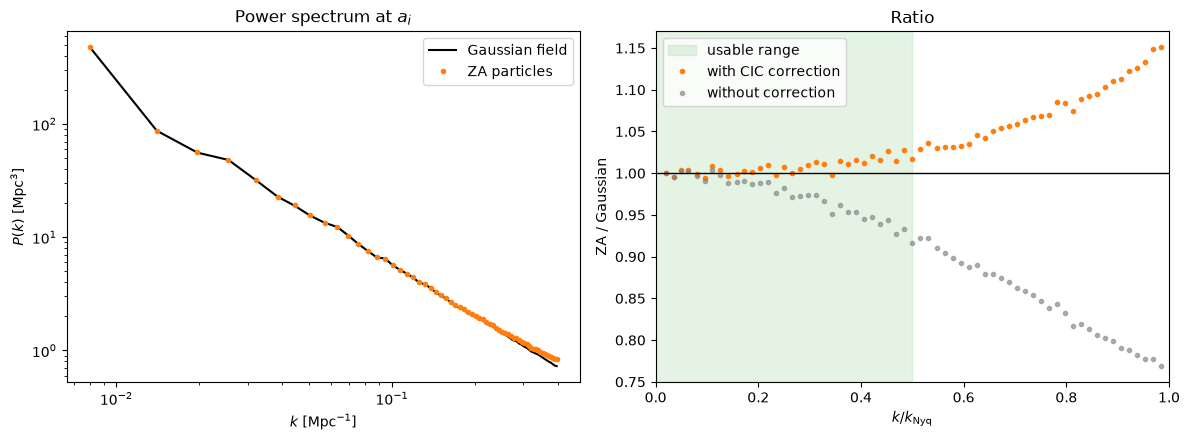

In [81]:
M = 2 * N # assignment mesh (twice finer than the particle lattice)
kNy = np.pi * N / L # particle Nyquist

delta_za, _ = cic_density(x, M, L)
dk_za = to_k(delta_za, L)
k_b, P_za,  Nk = power_spectrum(dk_za / cic_window(M, L), L, kmax=kNy) # with CIC correction
_,   P_raw, _  = power_spectrum(dk_za, L, kmax=kNy) # without correction
_,   P_g,   _  = power_spectrum(D1_i * dk_ref, L, kmax=kNy) # Gaussian field at a_i

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.5))

# The two spectra
ax1.loglog(k_b, P_g, 'k-', lw=1.5, label='Gaussian field')
ax1.loglog(k_b, P_za, 'o', ms=3, color='C1', label='ZA particles')
ax1.set_xlabel(r'$k\ [\mathrm{Mpc}^{-1}]$'); ax1.set_ylabel(r'$P(k)\ [\mathrm{Mpc}^3]$')
ax1.set_title(r'Power spectrum at $a_i$'); ax1.legend()

# Ratio
kk = k_b / kNy
ax2.axvspan(0, 0.5, color='C2', alpha=0.12, label='usable range')
ax2.plot(kk, P_za / P_g, 'o', ms=3, color='C1', label='with CIC correction')
ax2.plot(kk, P_raw / P_g, 'o', ms=3, color='gray', alpha=0.6, label='without correction')
ax2.axhline(1, color='k', lw=1)
ax2.set_xlim(0, 1)
ax2.set_xlabel(r'$k / k_\mathrm{Nyq}$'); ax2.set_ylabel('ZA / Gaussian')
ax2.set_title('Ratio'); ax2.legend()

fig.tight_layout(); fig.savefig(OUT / 'd_spectrum.png', dpi=150); plt.show()


In [82]:
# Unperturbed lattice assigned with CIC: where is its power?
d_lat, _ = cic_density(particle_load(N, L), M, L)
dk_lat = to_k(d_lat, L)
_, P_lat, _ = power_spectrum(dk_lat, L, kmax=kNy)
*_, kM = k_grid(M, L)
harm = np.unique(np.round(kM[np.abs(dk_lat) > 1e-6 * np.abs(dk_lat).max()] / kNy, 3))[:3]

print(f'lattice power for k < k_Nyq: max = {np.abs(P_lat).max():.1e} Mpc^3')
print(f'lattice power only at |k|/k_Nyq = {harm}')
print(f'Poisson shot noise V/N^3 = {L**3 / N**3:.1f} Mpc^3  vs  signal at a_i: '
      f'{D1_i**2 * P_ref(kNy/2):.2f} Mpc^3 (k_Nyq/2), {D1_i**2 * P_ref(kNy):.2f} Mpc^3 (k_Nyq)')

lattice power for k < k_Nyq: max = 0.0e+00 Mpc^3
lattice power only at |k|/k_Nyq = [2.    2.828 3.464]
Poisson shot noise V/N^3 = 476.8 Mpc^3  vs  signal at a_i: 2.00 Mpc^3 (k_Nyq/2), 0.71 Mpc^3 (k_Nyq)


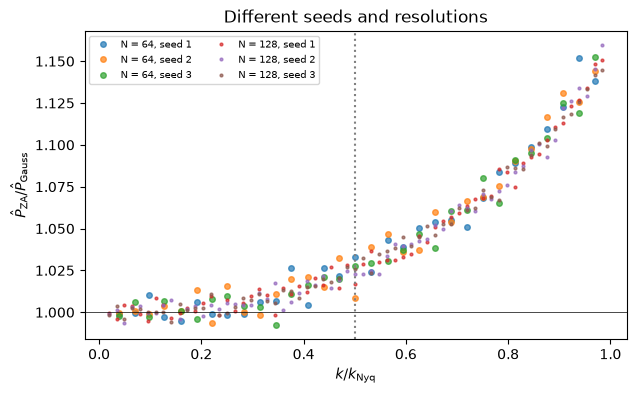

In [83]:
def za_ratio(Np, s):
    """P_ZA / P_Gaussian for Np^3 particles, seed s, CIC on a 2Np mesh."""
    dk_s = zero_nyquist(gaussian_field(Np, L, P_ref, s)[0])
    x_s = (particle_load(Np, L) + D1_i * za_displacement(dk_s, L)) % L
    d_s, _ = cic_density(x_s, 2 * Np, L)
    kn = np.pi * Np / L
    kb, Pz, _ = power_spectrum(to_k(d_s, L) / cic_window(2 * Np, L), L, kmax=kn)
    _,  Pg, _ = power_spectrum(D1_i * dk_s, L, kmax=kn)
    return kb / kn, Pz / Pg

fig, ax = plt.subplots(figsize=(7, 4))
for Np, mk in ((64, 'o'), (128, '.')):
    for s in (1, 2, 3):
        kk, r = za_ratio(Np, s)
        ax.plot(kk, r, mk, ms=4, alpha=0.7, label=f'N = {Np}, seed {s}')
ax.axhline(1, color='k', lw=0.5); ax.axvline(0.5, color='gray', ls=':')
ax.set_xlabel(r'$k / k_\mathrm{Nyq}$'); ax.set_ylabel(r'$\hat P_\mathrm{ZA} / \hat P_\mathrm{Gauss}$')
ax.set_title('Different seeds and resolutions'); ax.legend(fontsize=7, ncol=2)
fig.savefig(OUT / 'd_seeds_resolutions.png', dpi=150); plt.show()

The ZA particle spectrum reproduces the Gaussian field at the same epoch: within a few percent up to $k_\mathrm{Nyq}/2$, and both follow
$D_1^2(a_i)P_L$ within cosmic variance. Without the CIC correction the power is suppressed at high $k$. Above $k_\mathrm{Nyq}/2$ an excess grows
to $\sim 10\%$ at $k_\mathrm{Nyq}$. It is a property of the
lattice and the mass assignment, not noise, and the usable range is $k \lesssim k_\mathrm{Nyq}/2$.
